# Quando visitar Presidente Epitácio? Um calendário climático para o turismo

Presidente Epitácio (SP) é uma estância turística às margens do Rio Paraná, conhecida pela orla, pelas praias de rio e pela pesca. A pergunta deste projeto é simples e prática:

> **Em que meses, e em que horários, o clima favorece quem visita a cidade?**

A resposta é diferente para quem vem **nadar e curtir as praias** e para quem vem **passear na orla, pescar ou ir a eventos**. Por isso o projeto calcula um índice de conforto para cada um desses dois perfis.

**Dados:** estações meteorológicas automáticas do INMET, com uma leitura por hora.
**Ferramentas:** Python, pandas, NumPy e Matplotlib.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("src").resolve()))
import graficos as g
import indice_turismo as it
import processar as pr

g.estilo()
pd.set_option("display.precision", 1)

## 1. De onde vêm os dados

Presidente Epitácio não tem estação do INMET. As duas mais próximas são:

| Estação | Código | Distância do centro de Epitácio | Dados desde |
|---|---|---|---|
| Bataguassu (MS) | A759 | cerca de 37 km, do outro lado do Rio Paraná | 2013 |
| Presidente Prudente (SP) | A707 | cerca de 80 km | 2003 |

Bataguassu fica na mesma planície do rio, com altitude parecida, por isso é a base do calendário turístico. Presidente Prudente tem uma série mais longa e serve para olhar a **tendência** de calor nas últimas duas décadas.

Os arquivos brutos (um `.zip` por ano no [portal do INMET](https://portal.inmet.gov.br/dadoshistoricos)) são baixados com `python src/baixar_dados.py 2003 2025`.

In [2]:
horario = pr.carregar_horario()
diario = pr.agregar_diario(horario)
print(f"{len(horario):,} leituras horárias -> {len(diario):,} dias".replace(",", "."))
horario.head()

312.864 leituras horárias -> 13.038 dias


,chuva_mm,radiacao_kj,temp,temp_max,temp_min,umidade,vento_ms,momento,estacao,sensacao
0,0.0,NaN,26.9,27.5,26.9,62.0,2.1,2003-02-03 21:00:00,A707,26.9
1,0.0,NaN,26.6,26.9,26.2,58.0,1.7,2003-02-03 22:00:00,A707,26.6
2,0.0,NaN,25.3,26.7,25.3,64.0,0.6,2003-02-03 23:00:00,A707,25.3
3,0.0,NaN,25.1,25.7,25.1,69.0,0.5,2003-02-04 00:00:00,A707,25.1
4,0.0,NaN,24.8,25.1,24.6,71.0,1.2,2003-02-04 01:00:00,A707,24.8


## 2. Qualidade dos dados

Estações automáticas têm falhas: sensores que param, leituras `-9999` e valores impossíveis. O tratamento foi:

- leituras fora de faixas físicas (por exemplo, temperatura acima de 46 °C) viram ausentes;
- um dia só entra na análise se tiver **pelo menos 20 das 24 horas** registradas;
- as horas são convertidas de UTC para o horário de Brasília, o de Epitácio.

A tabela abaixo mostra quantos dias válidos cada estação tem por ano.

In [3]:
diario["ano"] = pd.to_datetime(diario["dia"]).dt.year
cobertura = (diario.groupby(["ano", "nome"])["temp_max"].count().unstack()
             .reindex(columns=["Bataguassu", "Presidente Prudente"]))
cobertura.fillna(0).astype(int).T

ano,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
nome,,,,,,,,,,,,,,,,,,,,,
Bataguassu,0,0,0,0,0,0,0,0,0,0,...,337,365,365,321,184,0,196,365,366,365
Presidente Prudente,87,41,347,345,363,366,363,338,365,366,...,305,365,365,365,366,365,306,365,353,362


Antes de usar Bataguassu como "o clima de Epitácio", vale conferir se as duas estações contam a mesma história. Se a temperatura máxima diária das duas andar junto, é um bom sinal de que a região tem um clima homogêneo.

In [4]:
pares = diario.pivot_table(index="dia", columns="nome", values="temp_max").dropna()
r = pares.corr().iloc[0, 1]
dif = (pares["Bataguassu"] - pares["Presidente Prudente"]).mean()
print(f"{len(pares)} dias em comum | correlação das máximas: {r:.2f} | Bataguassu é, em média, {dif:+.1f} °C")

3720 dias em comum | correlação das máximas: 0.95 | Bataguassu é, em média, +0.6 °C


## 3. O clima mês a mês

In [5]:
bata = diario[diario["estacao"] == "A759"].copy()
bata["mes"] = pd.to_datetime(bata["dia"]).dt.month
bata["ano"] = pd.to_datetime(bata["dia"]).dt.year

# Chuva mensal: só meses com pelo menos 25 dias medidos, para não subestimar.
chuva_mes = bata.groupby(["ano", "mes"])["chuva_mm"].agg(["sum", "count"])
chuva_mes = chuva_mes[chuva_mes["count"] >= 25]["sum"].groupby("mes").mean()

normais = bata.groupby("mes").agg(
    temp_max=("temp_max", "mean"), temp_min=("temp_min", "mean"),
    sensacao_max=("sensacao_max", "mean"), umidade_min=("umidade_min", "mean"),
    dias_35=("temp_max", lambda s: (s >= 35).mean() * 30.4),
)
normais["chuva_mm"] = chuva_mes
normais["dias_chuva"] = bata.groupby("mes")["chuva_mm"].apply(lambda s: (s >= 1).mean() * 30.4)
normais = normais.reset_index(drop=True)
normais.index = g.MESES
normais.round(1)

,temp_max,temp_min,sensacao_max,umidade_min,dias_35,chuva_mm,dias_chuva
Jan,33.0,22.2,34.4,46.9,5.4,159.0,8.6
Fev,32.5,22.2,34.2,49.5,4.8,153.1,9.7
Mar,32.5,21.8,34.0,47.9,3.8,100.3,6.9
Abr,30.4,19.9,30.7,46.8,2.2,108.4,5.1
Mai,28.1,17.4,27.7,46.5,0.5,62.6,4.3
Jun,27.2,16.3,26.5,44.9,0.0,46.9,3.7
Jul,27.5,15.2,26.3,37.0,0.0,28.7,2.4
Ago,29.2,16.1,27.8,32.1,2.9,43.5,2.9
Set,31.6,18.7,30.3,33.8,8.0,88.3,5.5
Out,31.7,20.4,31.7,42.7,6.3,141.6,6.6


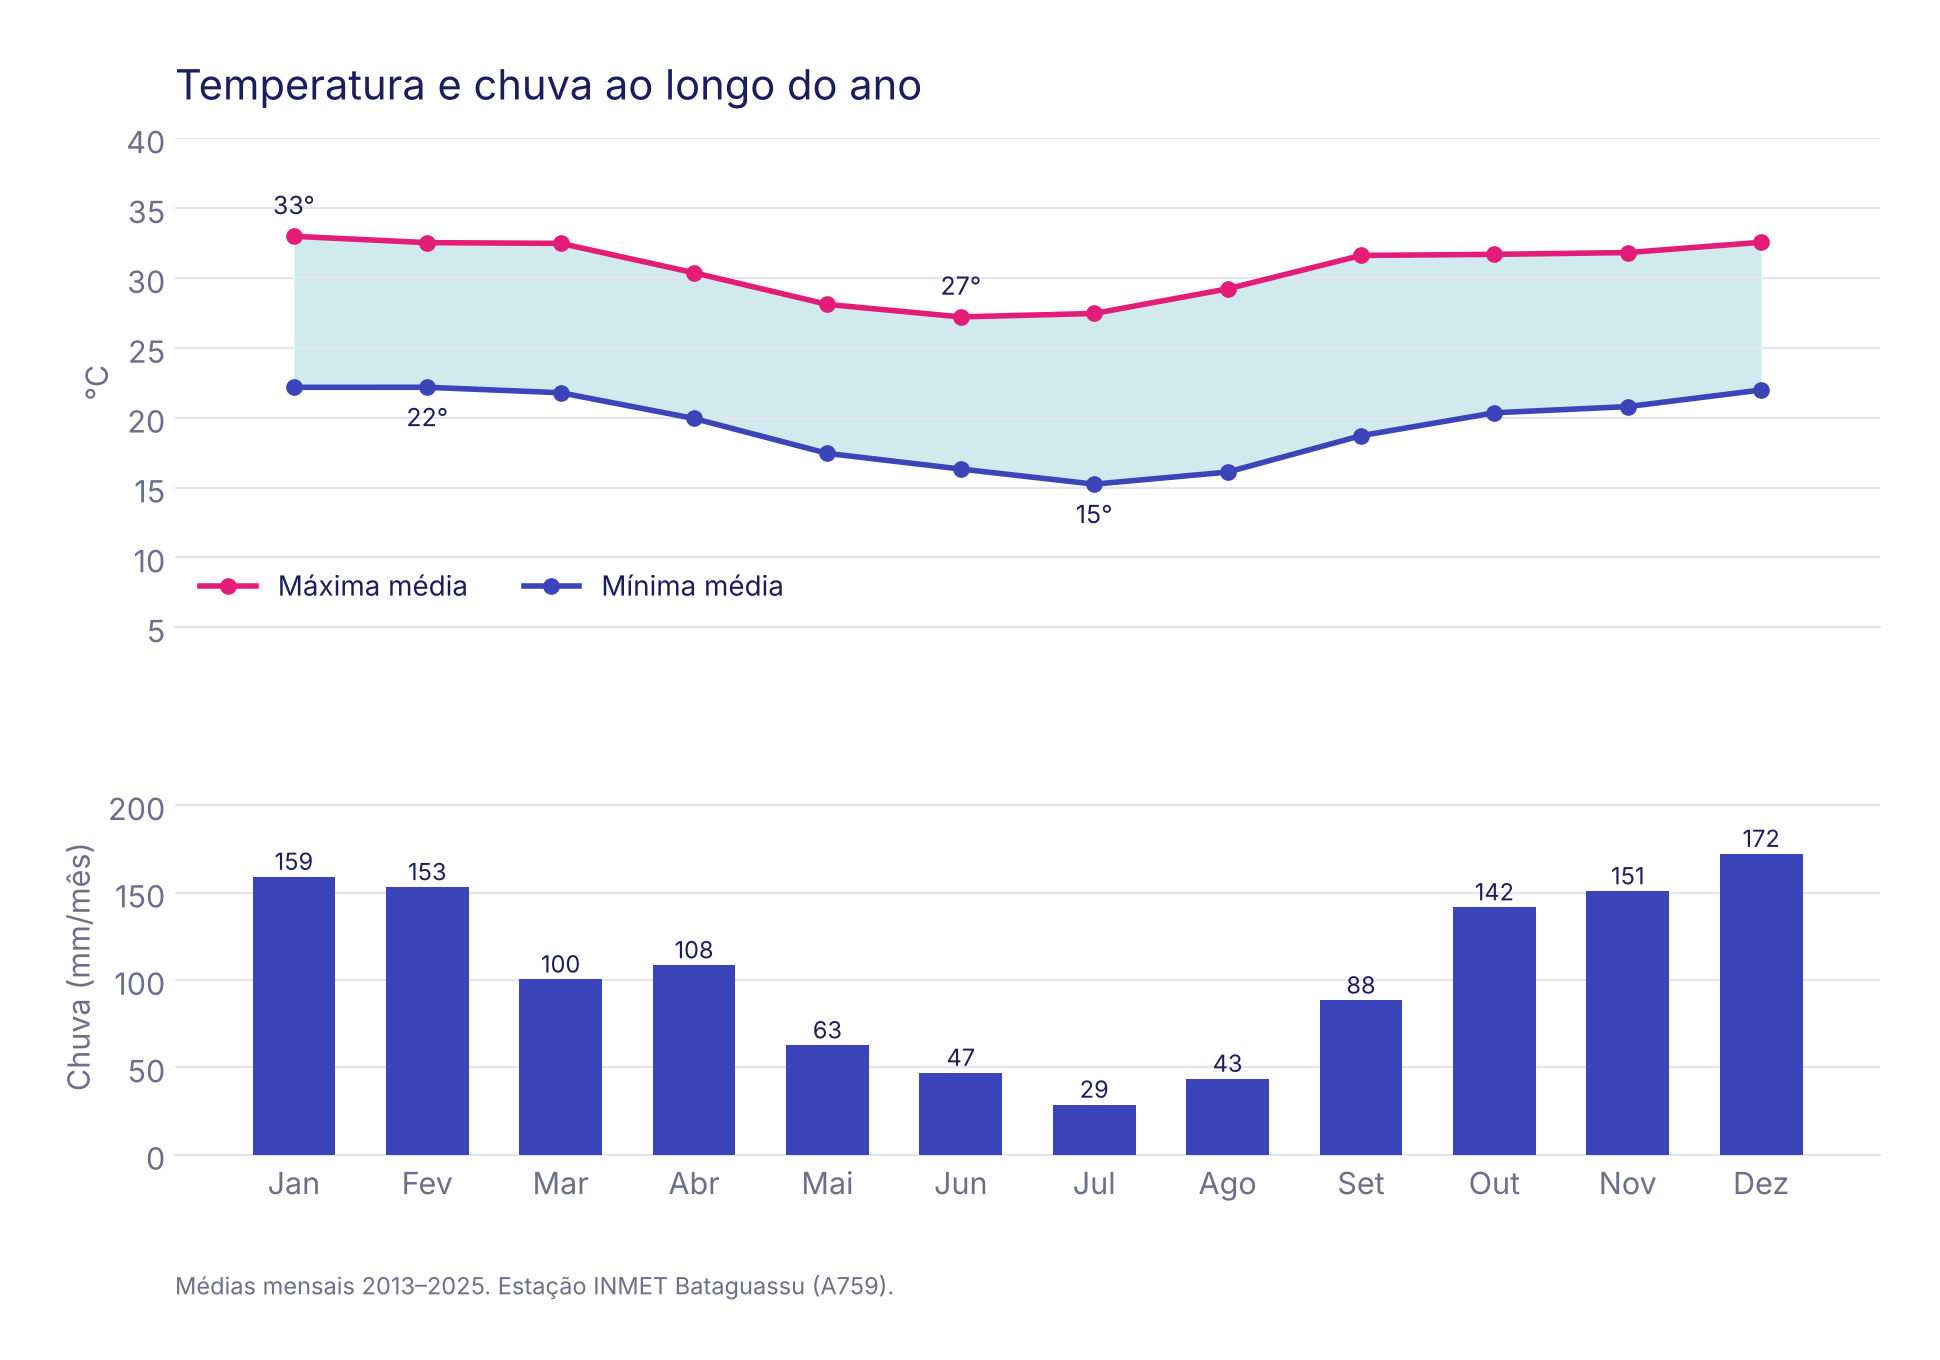

In [6]:
g.clima_mensal(normais.reset_index(drop=True));

## 4. Um índice de conforto para o turista

Para transformar o clima em algo útil para o turismo, usei uma adaptação do **Holiday Climate Index: Beach** (Scott, Rutty, Amelung e Tang, 2016), um índice criado para avaliar destinos de praia. Cada dia recebe quatro notas de 0 a 10:

| Componente | O que mede | Peso |
|---|---|---|
| Conforto térmico | sensação térmica máxima do dia | 2 |
| Céu aberto | radiação solar do dia comparada com um dia limpo do mesmo mês | 4 |
| Chuva | milímetros de chuva no dia | 3 |
| Vento | velocidade média do vento | 1 |

O resultado vai de 0 a 100. Dias com **70 ou mais** são considerados bons, e com 80 ou mais, excelentes.

**O que mudei em relação ao original:** o índice usa cobertura de nuvens, que o INMET não mede nas estações automáticas, então usei a radiação solar como aproximação. As faixas de conforto térmico também foram ajustadas para dois perfis de visitante:

- **Praia e rio:** sensação máxima ideal entre 28 e 33 °C (quem quer entrar na água);
- **Passeio, pesca e eventos:** sensação máxima ideal entre 22 e 28 °C.

In [7]:
praia = it.calcular(bata, "praia")
passeio = it.calcular(bata, "passeio")

# Dias sem dado completo (índice ausente) ficam fora da conta. Antes eles
# entravam no denominador como "não bons" e puxavam as porcentagens para baixo.
def resumo(df):
    return df.groupby("mes")["indice"].apply(lambda s: (s.dropna() >= 70).mean())

calendario = pd.DataFrame({"praia": resumo(praia), "passeio": resumo(passeio)})
calendario.index = g.MESES
(calendario * 100).round(0).astype(int).T

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
praia,55,56,60,62,70,71,70,71,67,62,58,55
passeio,45,47,51,59,74,73,73,71,63,56,50,43


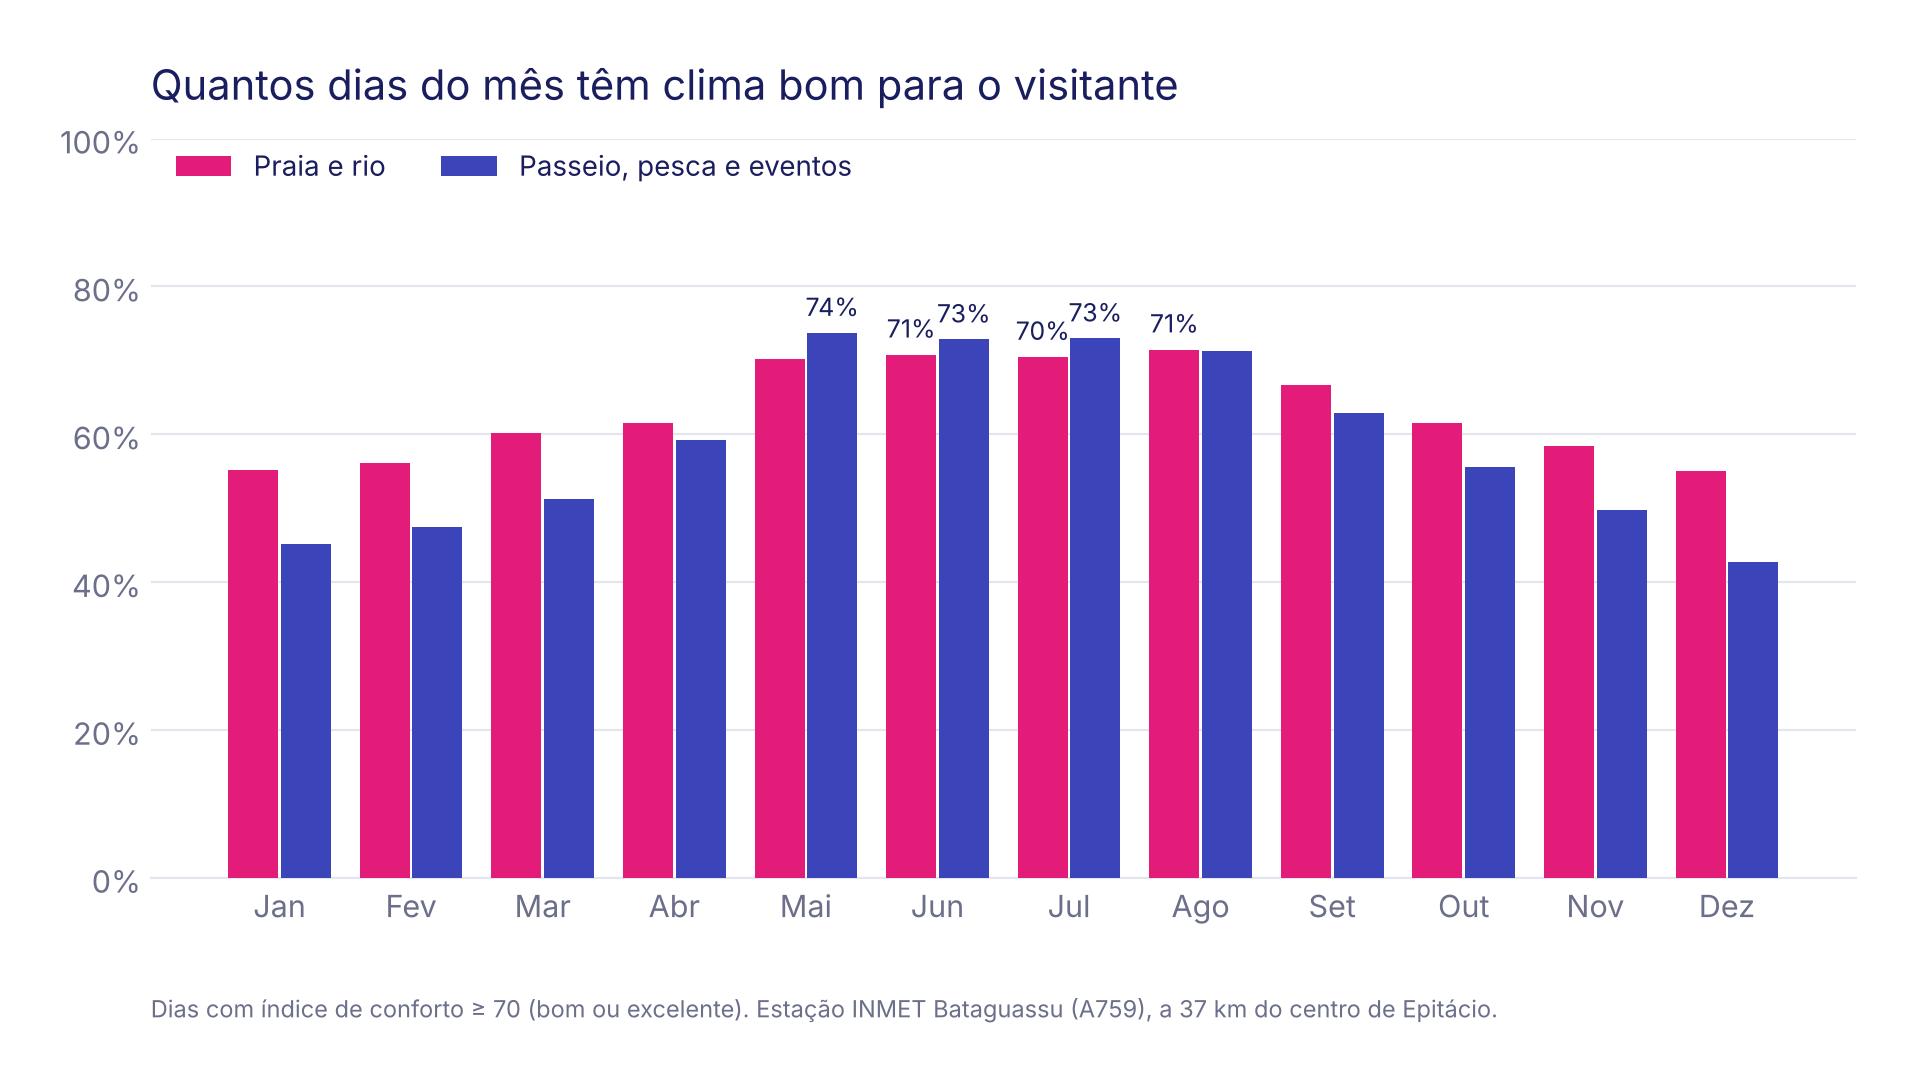

In [8]:
g.calendario(calendario.reset_index(drop=True));

O que puxa o índice para baixo em cada mês? A média de cada nota ajuda a explicar.

In [9]:
notas = praia.groupby("mes")[["nota_termica", "nota_sol", "nota_chuva", "nota_vento"]].mean()
notas["nota_termica_passeio"] = passeio.groupby("mes")["nota_termica"].mean()
notas.index = g.MESES
notas.round(1).T

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
nota_termica,7.0,7.1,7.5,8.3,7.7,7.4,7.3,7.6,7.7,7.6,7.8,7.7
nota_sol,7.6,7.3,7.8,7.8,7.6,8.0,8.2,7.8,7.3,7.2,7.2,7.4
nota_chuva,7.4,7.3,8.0,8.4,8.9,9.1,9.4,9.2,8.5,8.1,7.6,7.1
nota_vento,9.2,9.2,9.2,8.7,8.5,8.4,8.0,7.4,7.5,7.8,8.1,8.9
nota_termica_passeio,2.9,3.2,3.5,5.9,7.7,8.1,8.4,7.3,5.9,5.1,4.8,3.4


## 5. O melhor horário para a orla

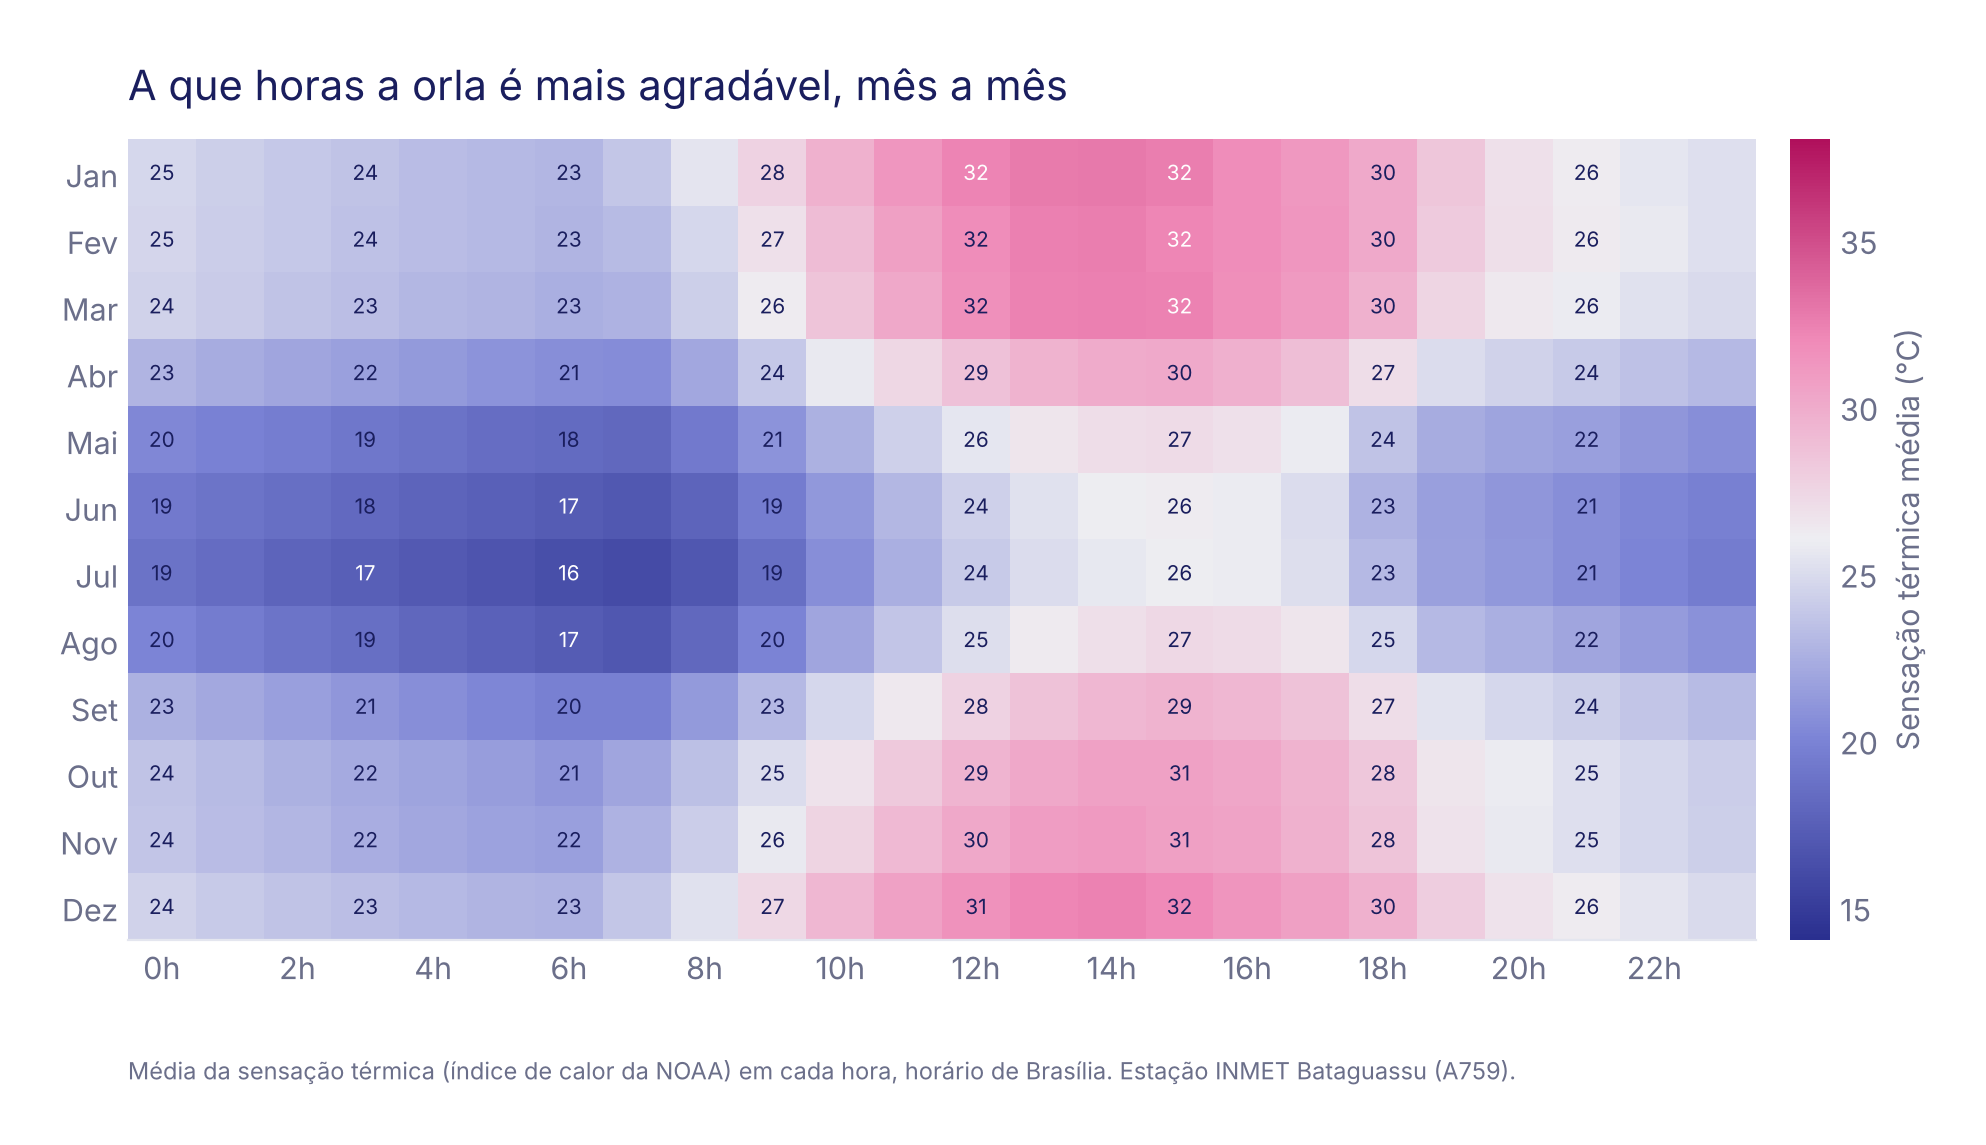

In [10]:
hb = horario[horario["estacao"] == "A759"].copy()
hb["mes"] = hb["momento"].dt.month
hb["hora"] = hb["momento"].dt.hour
por_hora = hb.pivot_table(index="mes", columns="hora", values="sensacao", aggfunc="mean")
g.mapa_horario(por_hora);

In [11]:
# Em cada mês: em que horas a sensação passa de 30 °C (melhor evitar sol na orla)
# e quantas horas do dia, entre 6h e 22h, ficam na faixa agradável de 20 a 28 °C.
def janela(linha):
    quentes = [h for h, v in linha.items() if v > 30]
    return f"{min(quentes)}h às {max(quentes) + 1}h" if quentes else "nenhuma"

def agradaveis(linha):
    return int(((linha.loc[6:22] >= 20) & (linha.loc[6:22] <= 28)).sum())

dicas = pd.DataFrame({
    "sensação acima de 30 °C": por_hora.apply(janela, axis=1),
    "horas agradáveis (6h–22h)": por_hora.apply(agradaveis, axis=1),
    "sensação às 18h (°C)": por_hora[18].round(1),
})
dicas.index = g.MESES
dicas

,sensação acima de 30 °C,horas agradáveis (6h–22h),sensação às 18h (°C)
Jan,11h às 19h,7,30.0
Fev,11h às 19h,7,30.1
Mar,11h às 18h,8,29.6
Abr,15h às 16h,11,27.0
Mai,nenhuma,14,23.6
Jun,nenhuma,13,22.7
Jul,nenhuma,13,23.0
Ago,nenhuma,13,24.7
Set,nenhuma,10,27.0
Out,13h às 17h,9,28.3


## 6. O calor está aumentando?

A série de Presidente Prudente começa em 2003, o que permite olhar duas décadas. Conto, em cada ano, quantos dias tiveram máxima de 35 °C ou mais. Anos com muitas falhas (menos de 330 dias válidos) ficam de fora, para não parecerem mais frescos do que foram.

ano,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2017,2018,2019,2020,2021,2023,2024,2025
dias_validos,347.0,345.0,363.0,366.0,363.0,338.0,365.0,366.0,363.0,365.0,360.0,365.0,365.0,365.0,366.0,365.0,365.0,353.0,362.0
dias_35,16.0,19.0,22.0,18.0,6.0,12.0,12.0,27.0,13.0,27.0,35.0,17.0,16.0,57.0,46.0,40.0,49.0,58.0,38.0
max_media,29.3,29.8,30.1,29.1,28.7,29.2,29.2,29.7,29.1,30.0,29.7,29.7,29.9,31.0,30.5,30.7,30.4,31.6,30.3


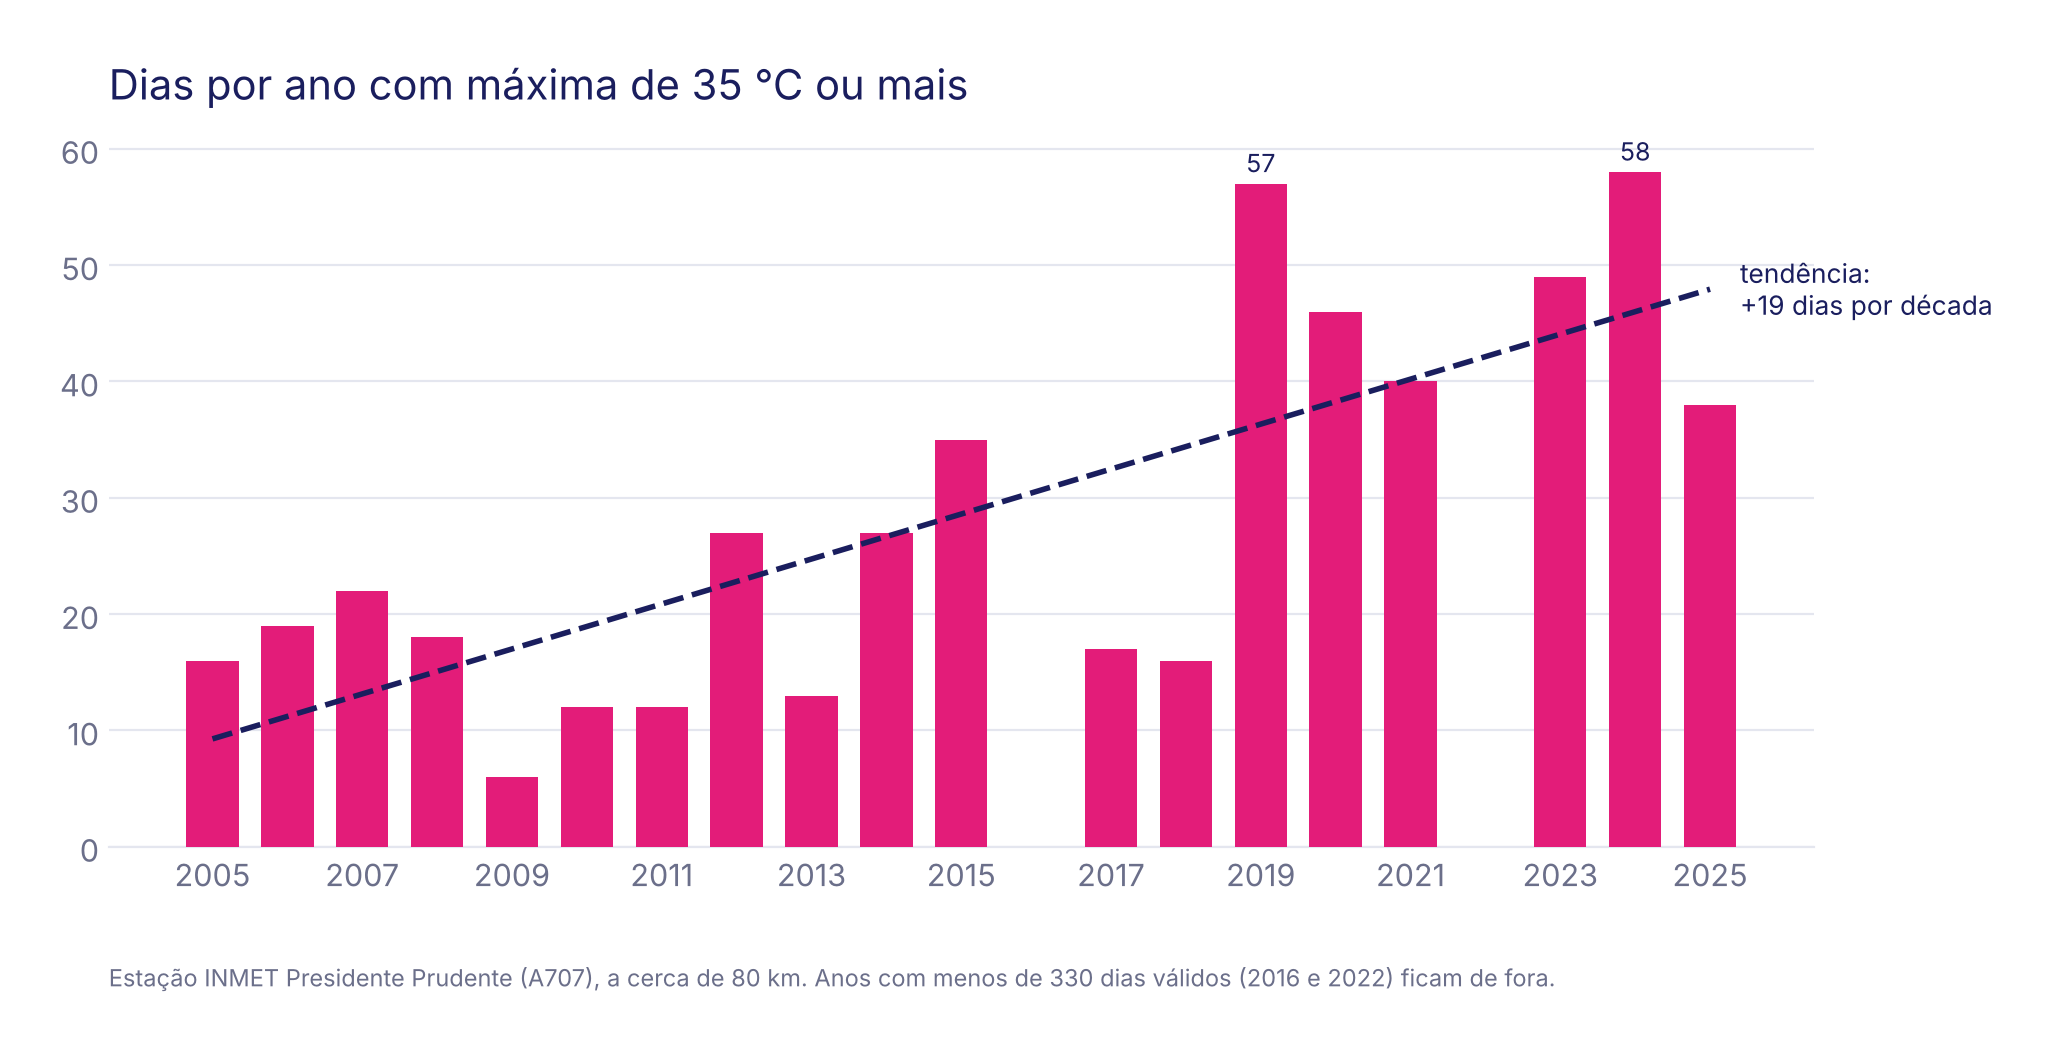

In [12]:
pp = diario[diario["estacao"] == "A707"]
anual = pp.groupby("ano").agg(dias_validos=("temp_max", "count"),
                              dias_35=("temp_max", lambda s: (s >= 35).sum()),
                              max_media=("temp_max", "mean"))
anual = anual[anual["dias_validos"] >= 330]
g.tendencia_calor(anual)
anual.round(1).T

In [13]:
inclinacao = np.polyfit(anual.index, anual["max_media"], 1)[0]
print(f"Máxima média anual: {inclinacao * 10:+.2f} °C por década")
print(f"Dias de 35 °C ou mais: {np.polyfit(anual.index, anual['dias_35'], 1)[0] * 10:+.1f} por década")

Máxima média anual: +0.86 °C por década
Dias de 35 °C ou mais: +19.3 por década


## 7. Conclusões

1. **De maio a agosto é a melhor época para visitar.** De 84% a 89% dos dias desses meses têm clima bom ou excelente para passeio, pesca e eventos, e de 80% a 86% para praia e rio. É a estação seca (de 29 a 63 mm de chuva por mês), com máximas médias entre 27 e 29 °C e nenhuma hora do dia com sensação acima de 30 °C, em média.
2. **Para praia e rio, o ano é mais equilibrado.** A porcentagem de dias bons varia de 67% (fevereiro) a 86% (julho), e março, abril e setembro ficam perto dos meses de inverno (79% a 81%). O verão perde pontos pelo calor excessivo (sensação máxima média de 34 °C) e pela chuva, que passa de 150 mm por mês. Para quem quer entrar na água, **abril e setembro** são um bom meio-termo: ainda quentes, com menos chuva que o verão.
3. **No verão, o horário faz diferença.** De dezembro a março, a sensação passa de 30 °C das 11h às 19h. A orla fica mais agradável até as 9h e depois das 20h. No inverno, o dia inteiro é confortável, e as noites ficam frescas (mínimas perto de 15 °C).
4. **O calor extremo está ficando mais comum.** Em Presidente Prudente, os dias com máxima de 35 °C ou mais passaram de uma média de 16 por ano (2005 a 2013) para 48 por ano (2019 a 2025). A máxima média anual subiu cerca de 0,9 °C por década. Para o turismo, isso reforça a importância de sombra, hidratação e programação nos horários mais frescos.

**Em uma frase:** quem quer passear, pescar ou ir a eventos encontra o melhor clima de maio a agosto; quem quer praia tem boas opções o ano todo, desde que fuja do sol do meio da tarde no verão.

## 8. Limitações

- **A estação não fica em Epitácio.** Bataguassu está a cerca de 37 km, na mesma planície do rio. A orla, bem ao lado da água, pode ser um pouco mais amena e úmida.
- **Sem temperatura da água nem nível do rio.** Para quem vai nadar, os dois importam, e o INMET não mede nenhum deles. A Agência Nacional de Águas (ANA) tem dados do nível do Rio Paraná, um bom próximo passo.
- **Céu aberto é uma aproximação.** A radiação solar mede bem dias nublados, mas não diferencia nuvem de fumaça de queimada, comum no inverno seco.
- **Faixas de conforto são escolhas.** Os limites de cada nota foram definidos neste projeto, inspirados no índice original. Mudar as faixas muda os números, mas não a ordem dos melhores meses (vale testar no `src/indice_turismo.py`).
- **Dias sem dado ficam fora das porcentagens.** Entre 12% e 24% dos dias de cada mês não têm medição completa (o índice fica ausente). Eles não entram na conta; numa versão anterior entravam como dias "não bons", o que subestimava as porcentagens, principalmente no verão.
- **Período curto.** Treze anos mostram o padrão sazonal, mas não substituem as normais climatológicas de 30 anos.